In [1]:
import pandas as pd, sqlite3, glob, kagglehub

# מוריד את הדאטה-סט ישירות מ-Kaggle
folder = kagglehub.dataset_download("janiobachmann/bank-marketing-dataset")
path = glob.glob(folder + '/**/*.csv', recursive=True)[0]
df = pd.read_csv(path, sep=None, engine='python')
target = 'y' if 'y' in df.columns else 'deposit'
df = df.rename(columns={target: 'subscribed'})
print(df.shape)

# מכניס את הנתונים לבסיס נתונים כדי לעבוד עם SQL
conn = sqlite3.connect(':memory:')
df.to_sql('customers', conn, index=False)
def sql(q): return pd.read_sql(q, conn)

# שאילתת SQL ראשונה: כמה לקוחות נענו לקמפיין וכמה לא
sql("""
SELECT subscribed, COUNT(*) AS customers
FROM customers
GROUP BY subscribed
""")

(11162, 17)


,subscribed,customers
0,no,5873
1,yes,5289


In [2]:
sql("""
SELECT job,
       COUNT(*) AS customers,
       ROUND(100.0 * SUM(CASE WHEN subscribed = 'yes' THEN 1 ELSE 0 END) / COUNT(*), 1) AS response_rate
FROM customers
GROUP BY job
ORDER BY response_rate DESC
""")

,job,customers,response_rate
0,student,360,74.7
1,retired,778,66.3
2,unemployed,357,56.6
3,management,2566,50.7
4,unknown,70,48.6
5,admin.,1334,47.3
6,self-employed,405,46.2
7,technician,1823,46.1
8,services,923,40.0
9,housemaid,274,39.8


In [3]:
sql("""
SELECT CASE
         WHEN age < 30 THEN '1. under 30'
         WHEN age < 40 THEN '2. 30-39'
         WHEN age < 50 THEN '3. 40-49'
         WHEN age < 60 THEN '4. 50-59'
         ELSE '5. 60+'
       END AS age_group,
       COUNT(*) AS customers,
       ROUND(100.0 * SUM(CASE WHEN subscribed = 'yes' THEN 1 ELSE 0 END) / COUNT(*), 1) AS response_rate
FROM customers
GROUP BY age_group
ORDER BY age_group
""")

,age_group,customers,response_rate
0,1. under 30,1551,59.8
1,2. 30-39,4318,44.3
2,3. 40-49,2628,40.4
3,4. 50-59,1885,41.6
4,5. 60+,780,76.9


In [4]:
sql("""
SELECT housing AS has_mortgage,
       loan AS has_personal_loan,
       COUNT(*) AS customers,
       ROUND(100.0 * SUM(CASE WHEN subscribed = 'yes' THEN 1 ELSE 0 END) / COUNT(*), 1) AS response_rate
FROM customers
GROUP BY housing, loan
ORDER BY response_rate DESC
""")


,has_mortgage,has_personal_loan,customers,response_rate
0,no,no,5256,59.6
1,yes,no,4446,37.6
2,no,yes,625,35.0
3,yes,yes,835,31.7


In [5]:
sql("""
SELECT poutcome AS previous_campaign,
       COUNT(*) AS customers,
       ROUND(100.0 * SUM(CASE WHEN subscribed = 'yes' THEN 1 ELSE 0 END) / COUNT(*), 1) AS response_rate
FROM customers
GROUP BY poutcome
ORDER BY response_rate DESC
""")

,previous_campaign,customers,response_rate
0,success,1071,91.3
1,other,537,57.2
2,failure,1228,50.3
3,unknown,8326,40.7


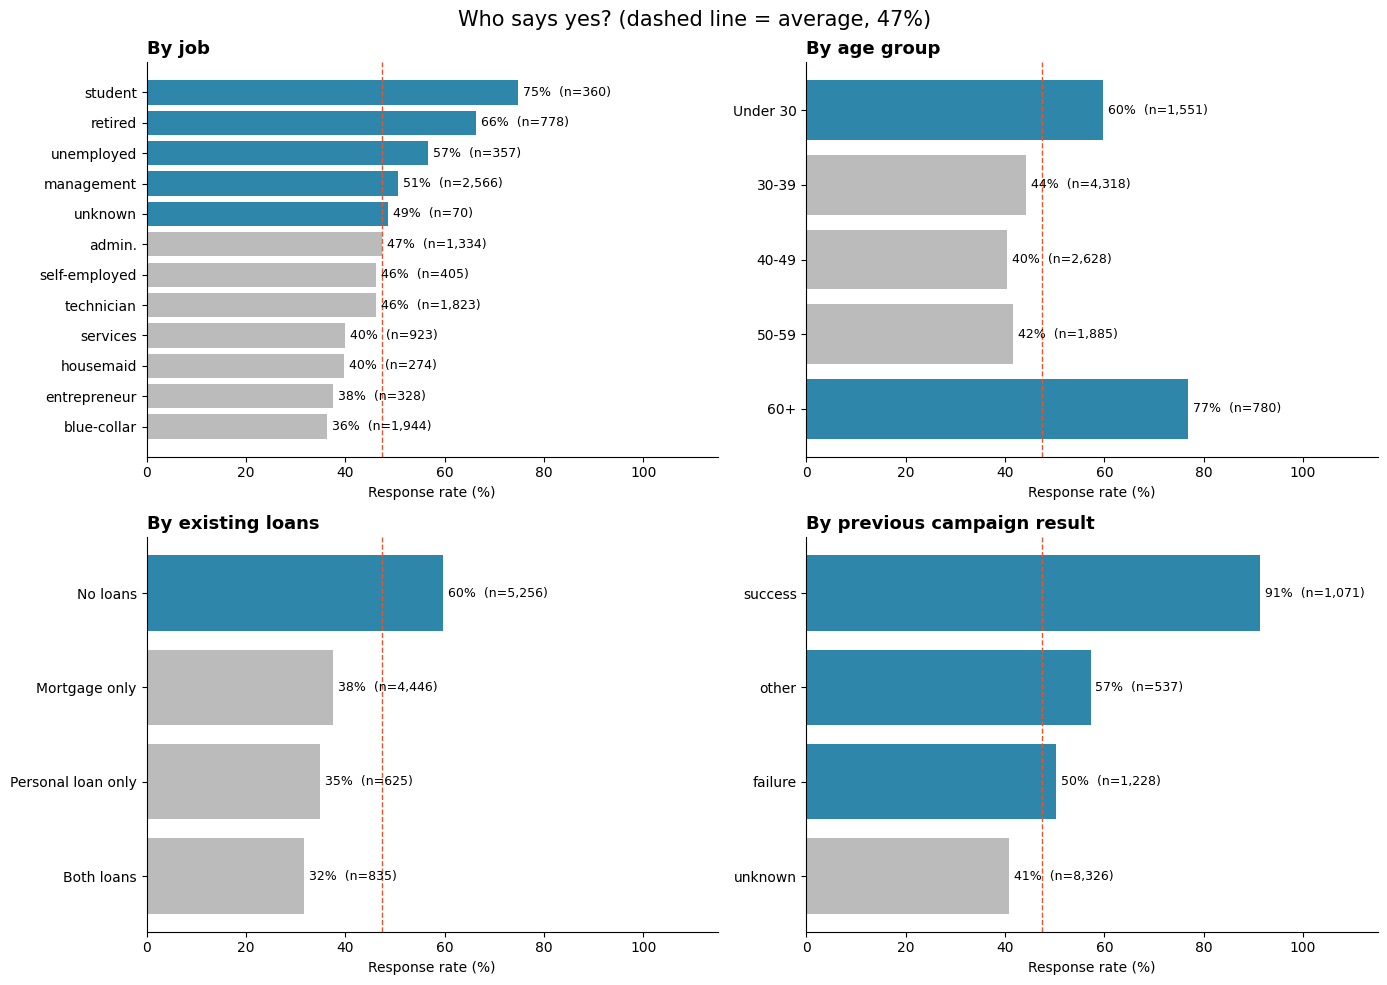

In [6]:
import matplotlib.pyplot as plt

RATE = "ROUND(100.0*SUM(CASE WHEN subscribed='yes' THEN 1 ELSE 0 END)/COUNT(*),1)"
avg = sql(f"SELECT {RATE} AS r FROM customers")['r'][0]

def by(group_expr, order='response_rate DESC'):
    q = f"SELECT {group_expr} AS grp, COUNT(*) AS customers, {RATE} AS response_rate"
    q += f" FROM customers GROUP BY grp ORDER BY {order}"
    return sql(q)

age_expr = """CASE WHEN age<30 THEN 'Under 30' WHEN age<40 THEN '30-39'
               WHEN age<50 THEN '40-49' WHEN age<60 THEN '50-59' ELSE '60+' END"""
loan_expr = """CASE WHEN housing='no' AND loan='no' THEN 'No loans'
                WHEN housing='yes' AND loan='no' THEN 'Mortgage only'
                WHEN housing='no' AND loan='yes' THEN 'Personal loan only'
                ELSE 'Both loans' END"""

panels = [(by('job'), 'By job'),
          (by(age_expr, 'MIN(age)'), 'By age group'),
          (by(loan_expr), 'By existing loans'),
          (by('poutcome'), 'By previous campaign result')]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, (d, title) in zip(axes.flat, panels):
    colors = ['#2E86AB' if r >= avg else '#BBBBBB' for r in d['response_rate']]
    ax.barh(d['grp'], d['response_rate'], color=colors)
    ax.invert_yaxis()
    ax.axvline(avg, color='#E4572E', linestyle='--', linewidth=1)
    for y, (r, n) in enumerate(zip(d['response_rate'], d['customers'])):
        ax.text(r + 1, y, f'{r:.0f}%  (n={n:,})', va='center', fontsize=9)
    ax.set_title(title, fontsize=13, loc='left', fontweight='bold')
    ax.set_xlim(0, 115)
    ax.set_xlabel('Response rate (%)')
    for s in ['top', 'right']:
        ax.spines[s].set_visible(False)

main_title = f'Who says yes? (dashed line = average, {avg:.0f}%)'
fig.suptitle(main_title, fontsize=15)
plt.tight_layout()
plt.savefig('dashboard.png', dpi=150, bbox_inches='tight')
plt.show()

## Key Findings & Recommendations

1. **Past success is the strongest predictor.** 91% of customers who said yes in the previous campaign said yes again, vs. 41% of customers with no prior contact.
2. **Existing debt lowers response.** Customers with no loans responded at 60%, vs. 32% for customers with both a mortgage and a personal loan.
3. **Age shows a U-shape.** Customers under 30 (60%) and over 60 (77%) respond most; ages 30–59 respond around 40–44%.
4. **Students and retirees lead; blue-collar workers trail** (75% and 66% vs. 36%).

**Recommendation:** Prioritize previous responders and customers without existing loans, and give extra focus to the under-30 and 60+ segments.

*Note: this dataset is roughly balanced between yes/no, so the absolute rates are higher than in a real campaign. The comparisons between groups are what matter.*